# 01 – Exploratory Data Analysis
UCI Heart Disease (Cleveland). Target: 0 = no disease, 1 = disease (original 1–4 collapsed).

In [1]:
import os; os.chdir('..')
import pandas as pd
from IPython.display import Image, display
from src import eda
from src.data import CLEAN_PATH
df = pd.read_csv(CLEAN_PATH)
df.shape

(303, 14)

In [2]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [4]:
df.isna().sum()[lambda s: s > 0]

ca      4
thal    2
dtype: int64

`ca` and `thal` contain a few missing values. They are kept as NaN and imputed **inside** the model pipeline (median for numeric, most-frequent for categorical) so imputation is fit on training folds only.

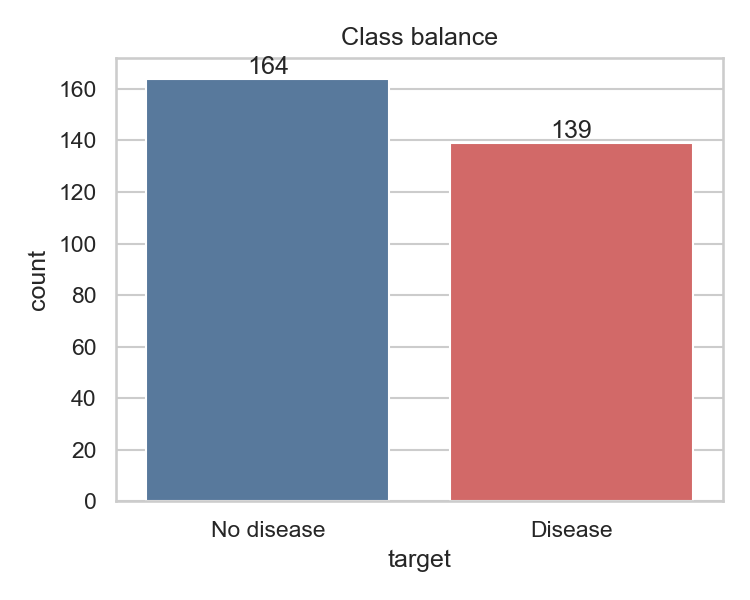

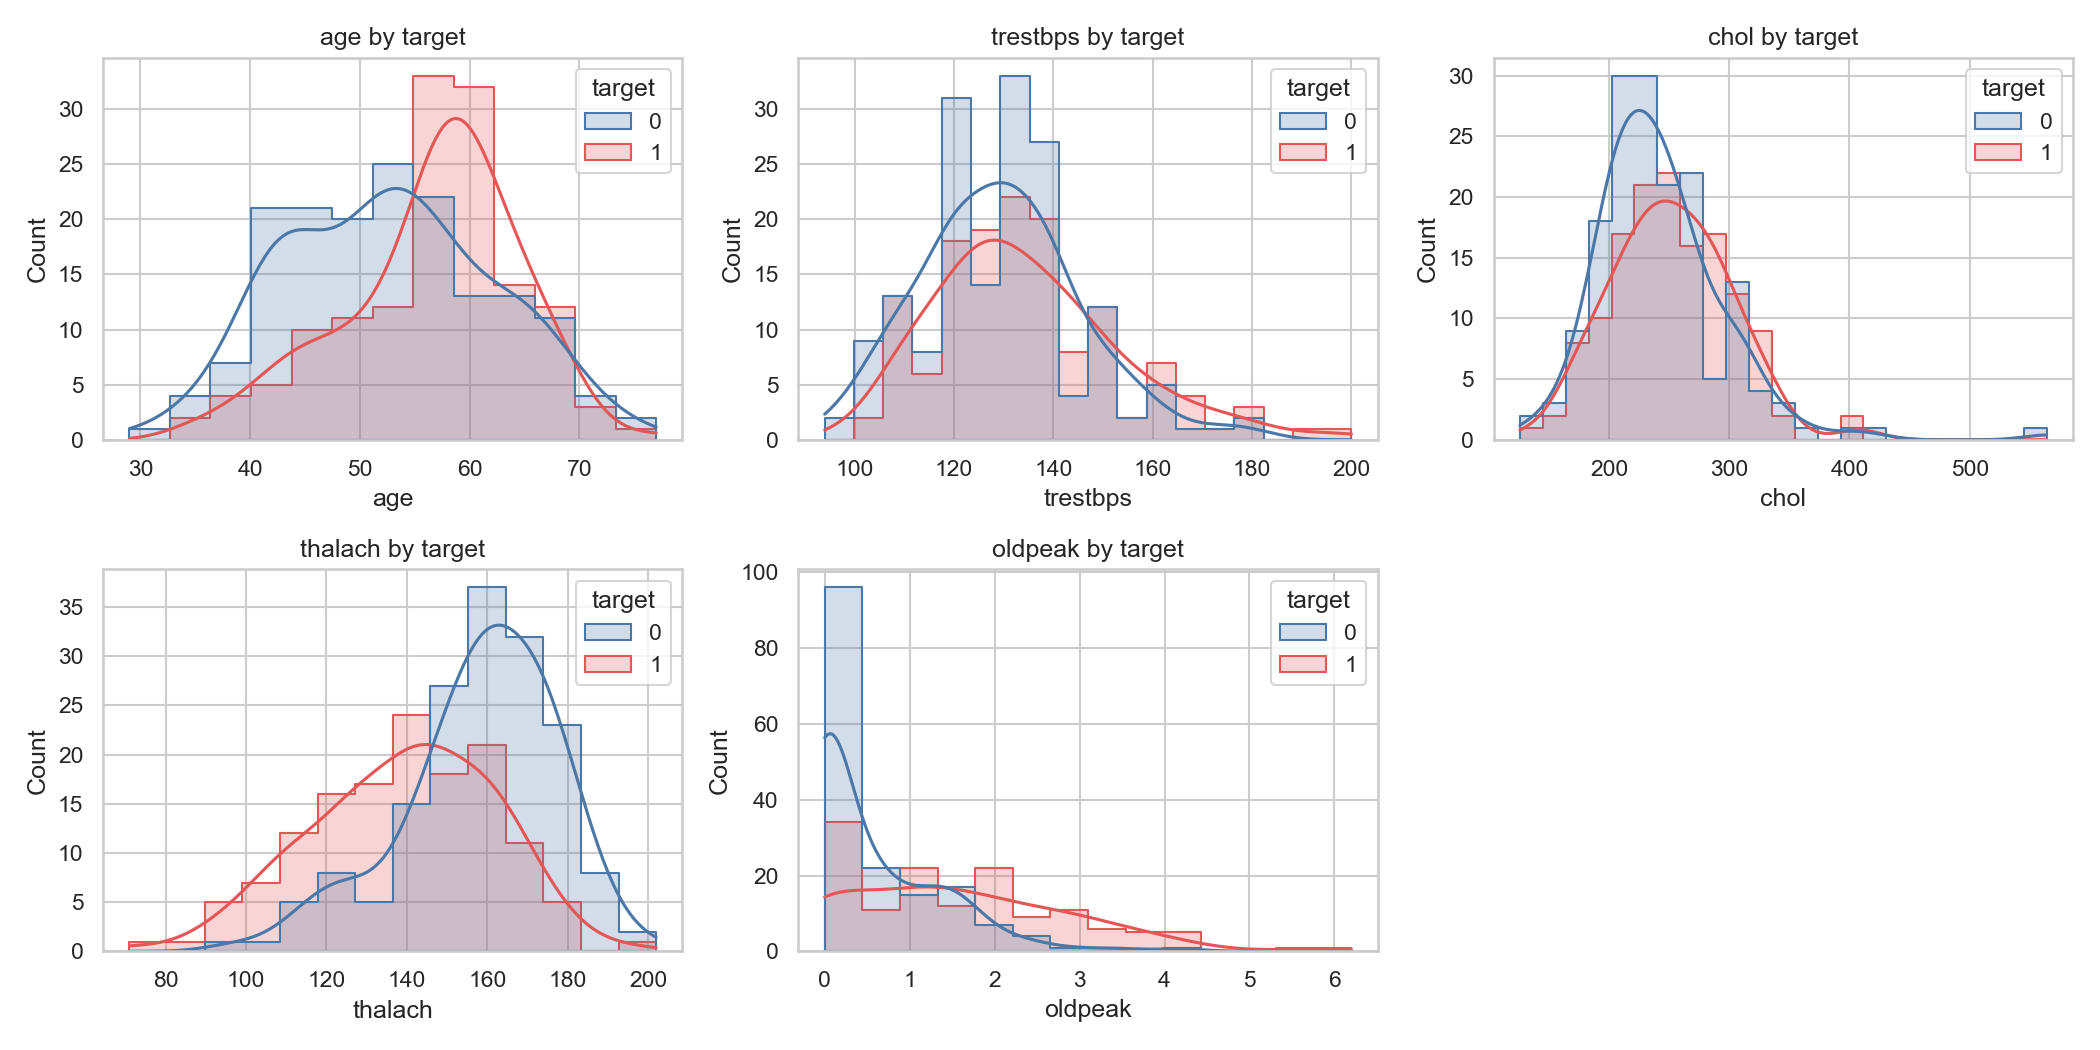

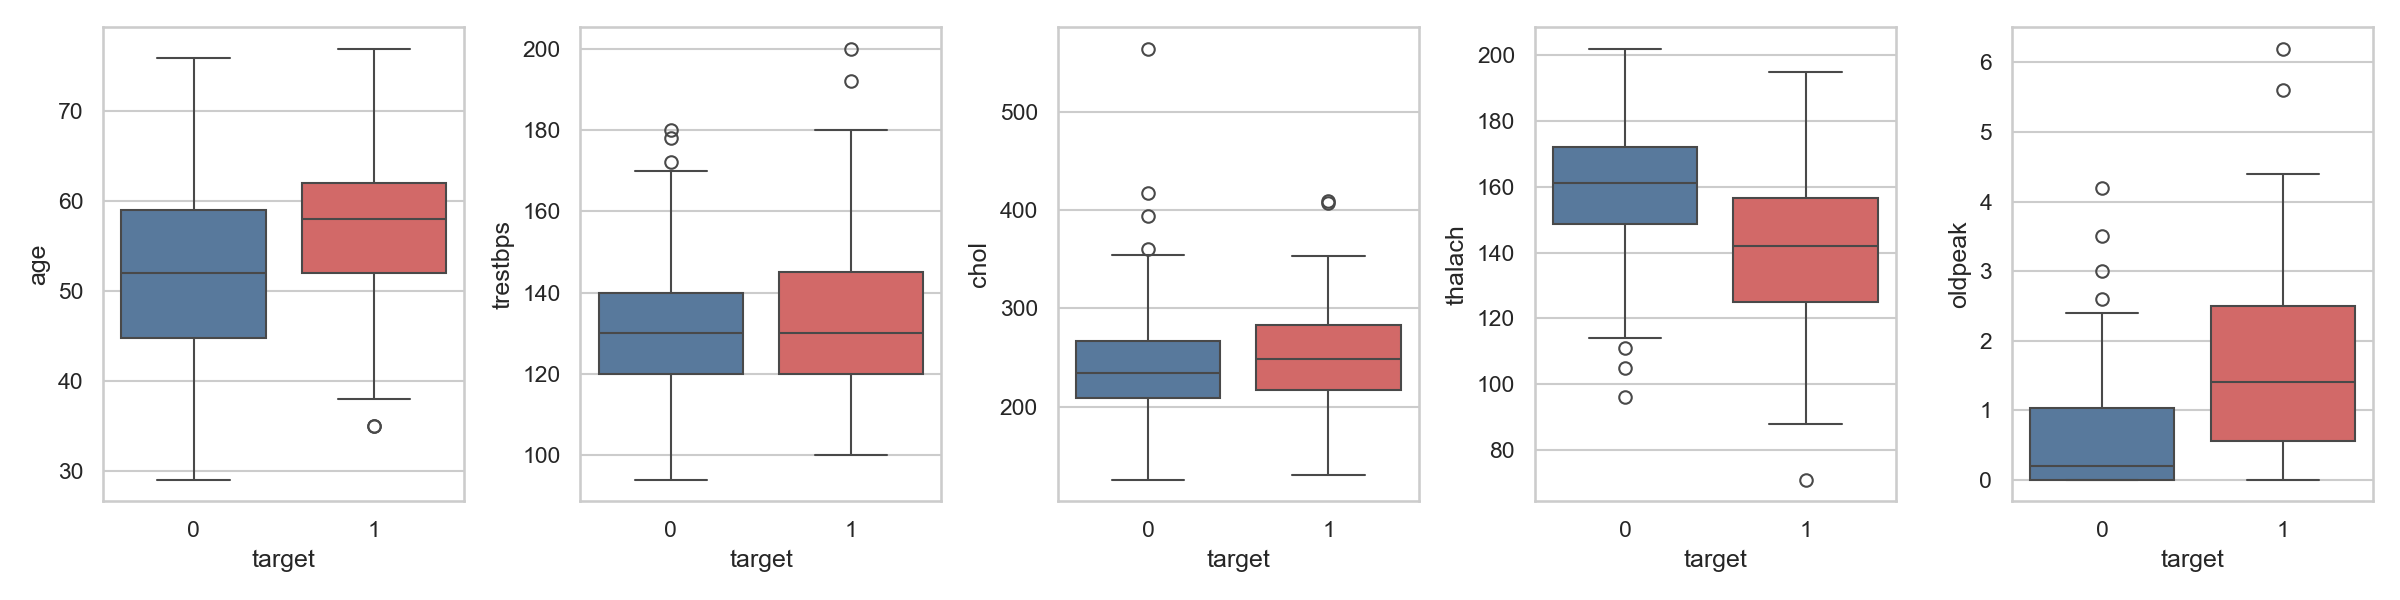

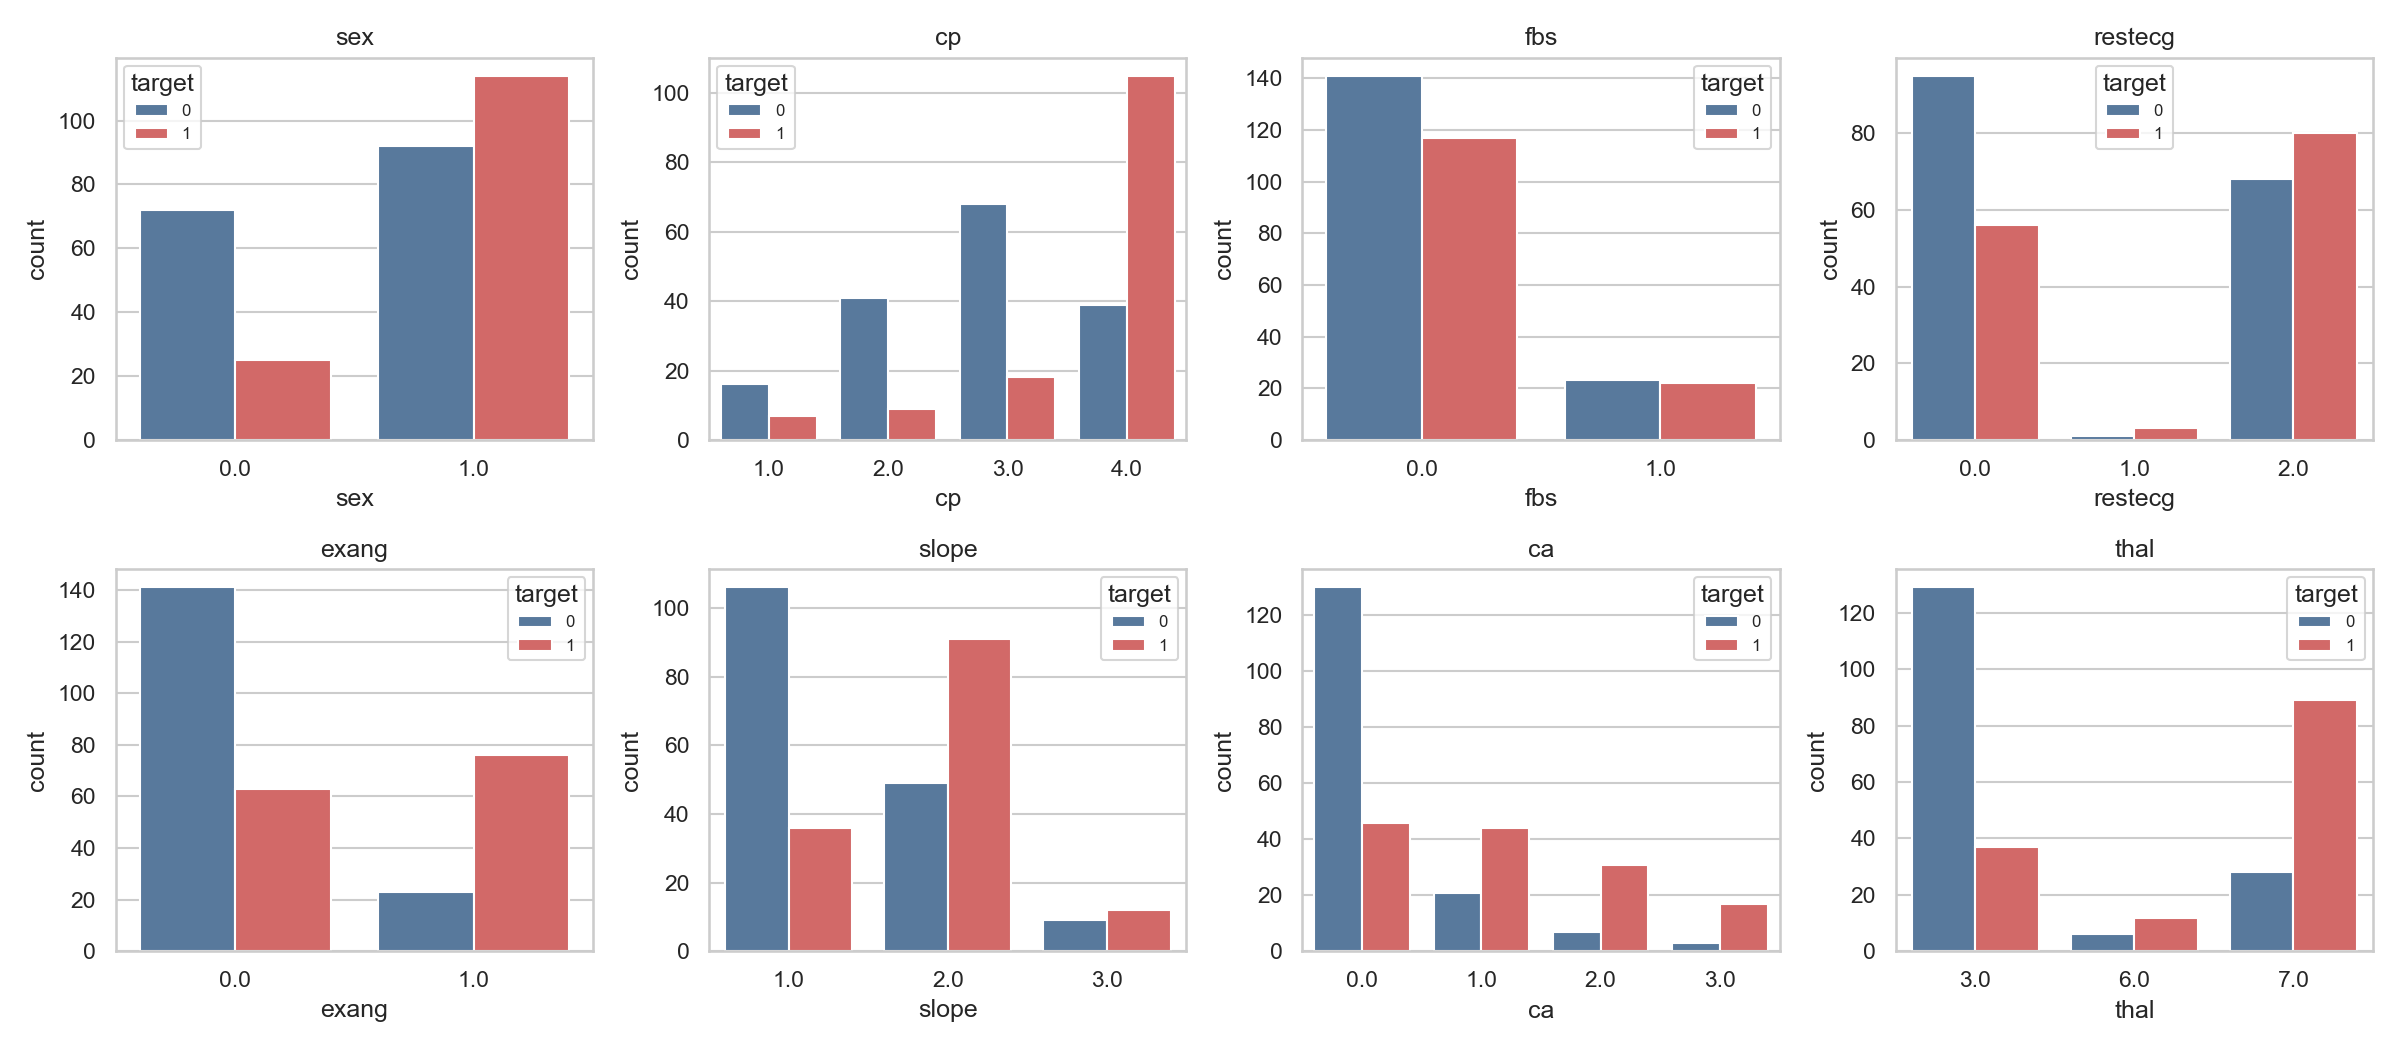

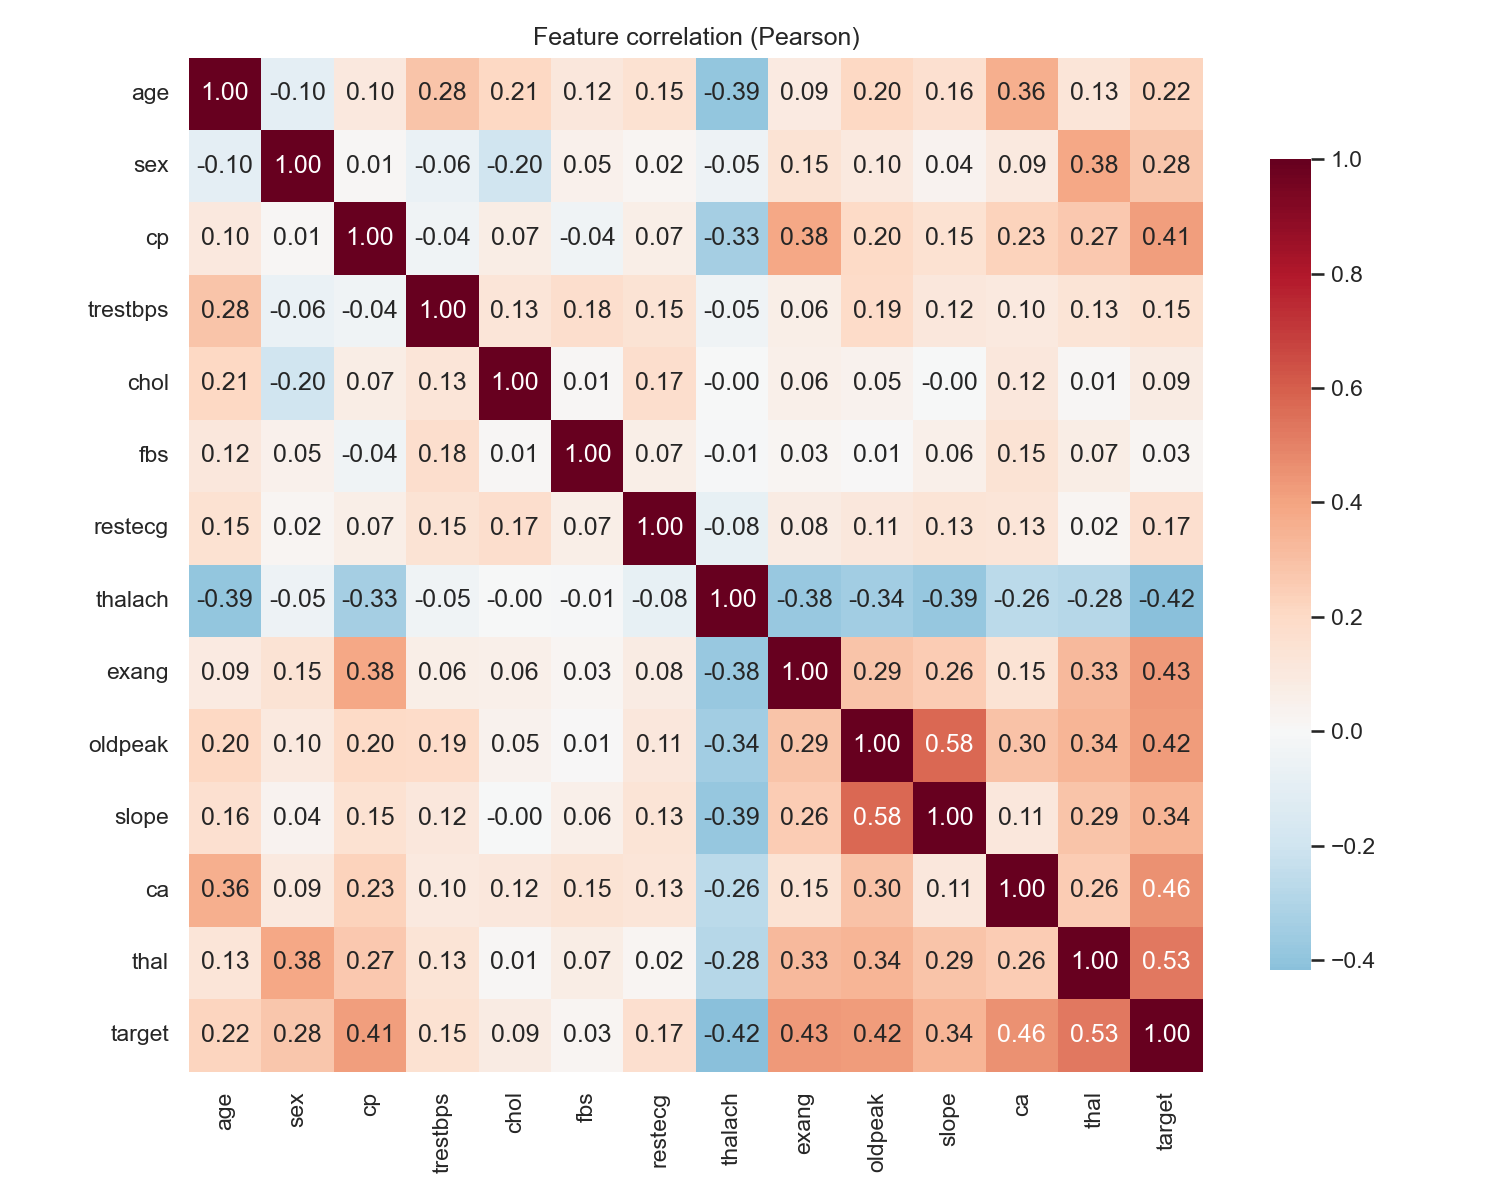

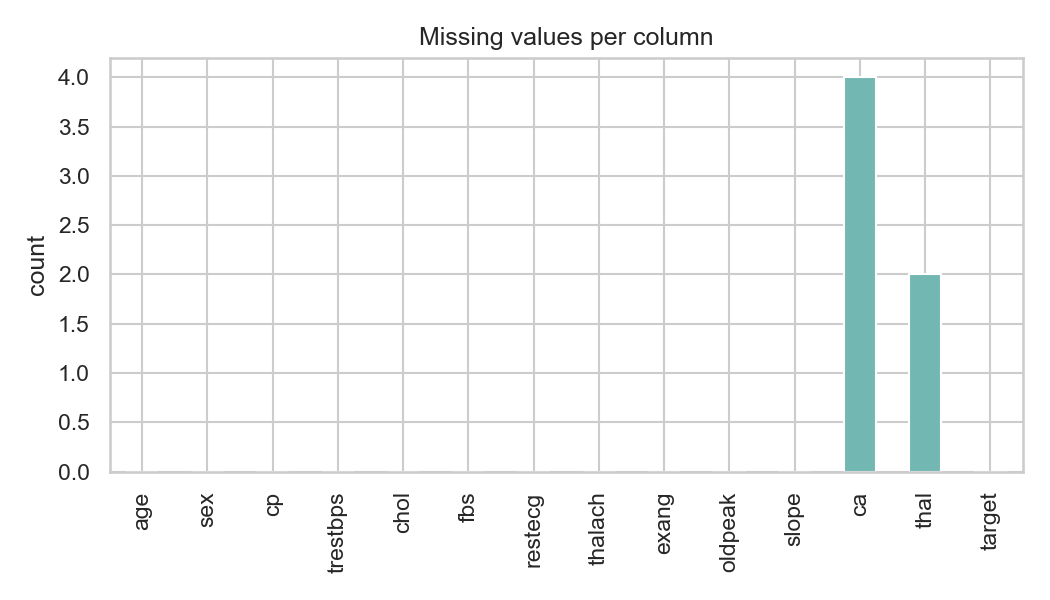

In [5]:
figs = eda.run()
for f in figs:
    display(Image(str(f)))

## Findings
- Classes are close to balanced, so accuracy is meaningful and no resampling is needed.
- `thalach` (max heart rate) is negatively associated with disease; `oldpeak`, `ca`, `exang` and `cp` are positively associated.
- Correlations between predictors are moderate, so Logistic Regression is not badly affected by multicollinearity.
- Numeric features have different scales, so standardisation is required for Logistic Regression.